# Agrupación de viviendas en California

Pregunta: clasificar grupos de bloques del censo de California de 1990 según la región y el ingreso mediano.

Columnas del modelo, en este orden: `Latitude`, `Longitude` y `MedInc`. El enunciado fija 6 clusters. El archivo es la copia local de `housing.csv` del tutorial, comprobada por sha256.

El cálculo vive en `src/housing_clusters.py`. Este cuaderno lo ejecuta y muestra cada paso.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "housing_clusters.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from housing_clusters import run_pipeline

result = run_pipeline()
print("filas", result["info"]["n_rows"], "train", result["n_train"], "test", result["n_test"])


Cargando housing.csv...


Filas 20640. Entrenamiento 16512. Prueba 4128.


Ajustando K-Means (k=6)...


Calculando inercia y silhouette para k=2..10...


  diagnóstico k=2


  diagnóstico k=3


... (10 outputs left out)

  validando knn


  validando random_forest


Modelos guardados.


filas 20640 train 16512 test 4128


## Paso 1. Carga y división

Se leen las 20640 filas, se comprueba el sha256 oficial y se dejan solo las tres columnas del enunciado. La división es 80/20 con semilla 42. El enunciado no fija el porcentaje.


In [2]:
info = result["info"]
print("sha256", info["sha256"])
print("bytes", info["bytes"])
print("columnas del archivo", info["columns_file"])
print("columnas usadas", info["columns_used"])
print("columnas fuera del modelo", info["columns_unused"])
print(f"entrenamiento {result['n_train']}  prueba {result['n_test']}  test_size {result['test_size']}  semilla {result['random_state']}")
display(result["head"])
display(result["describe"])


sha256 0e4a0bc8b337d88c95259a8ec05a58c662f26f87487f9cbf2448fe93207bcb5c
bytes 1959699
columnas del archivo ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
columnas usadas ['Latitude', 'Longitude', 'MedInc']
columnas fuera del modelo ['HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'MedHouseVal']
entrenamiento 16512  prueba 4128  test_size 0.2  semilla 42


,Latitude,Longitude,MedInc
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462


,count,mean,std,min,25%,50%,75%,max
Latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
Longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
MedInc,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001


## Paso 2. K-Means con 6 clusters

`StandardScaler` se ajusta con el entrenamiento. K-Means usa k = 6, diez inicializaciones y la semilla 42. La predicción llega como entero; la columna `cluster` se guarda como categoría 0–5.


Pipeline(steps=[('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=6, n_init=10, random_state=42))])
dtype de la predicción: int32
dtype de la columna: category
valores: [0, 1, 2, 3, 4, 5]
conteo en entrenamiento


,n
cluster,
0,1321
1,3380
2,453
3,3931
4,2239
5,5188


En el entrenamiento, la desviación típica es 2.14 en latitud, 2.01 en longitud y 1.90 en MedInc. Las cifras brutas se parecen, pero las unidades no: grados frente a la escala de ingreso del archivo. StandardScaler se ajusta solo con el entrenamiento y K-Means usa la distancia euclídea en ese espacio.


,feature,mean,std,min,max
0,Latitude,35.643149,2.136665,32.5500,41.9500
1,Longitude,-119.582290,2.005654,-124.3500,-114.3100
2,MedInc,3.880754,1.904294,0.4999,15.0001


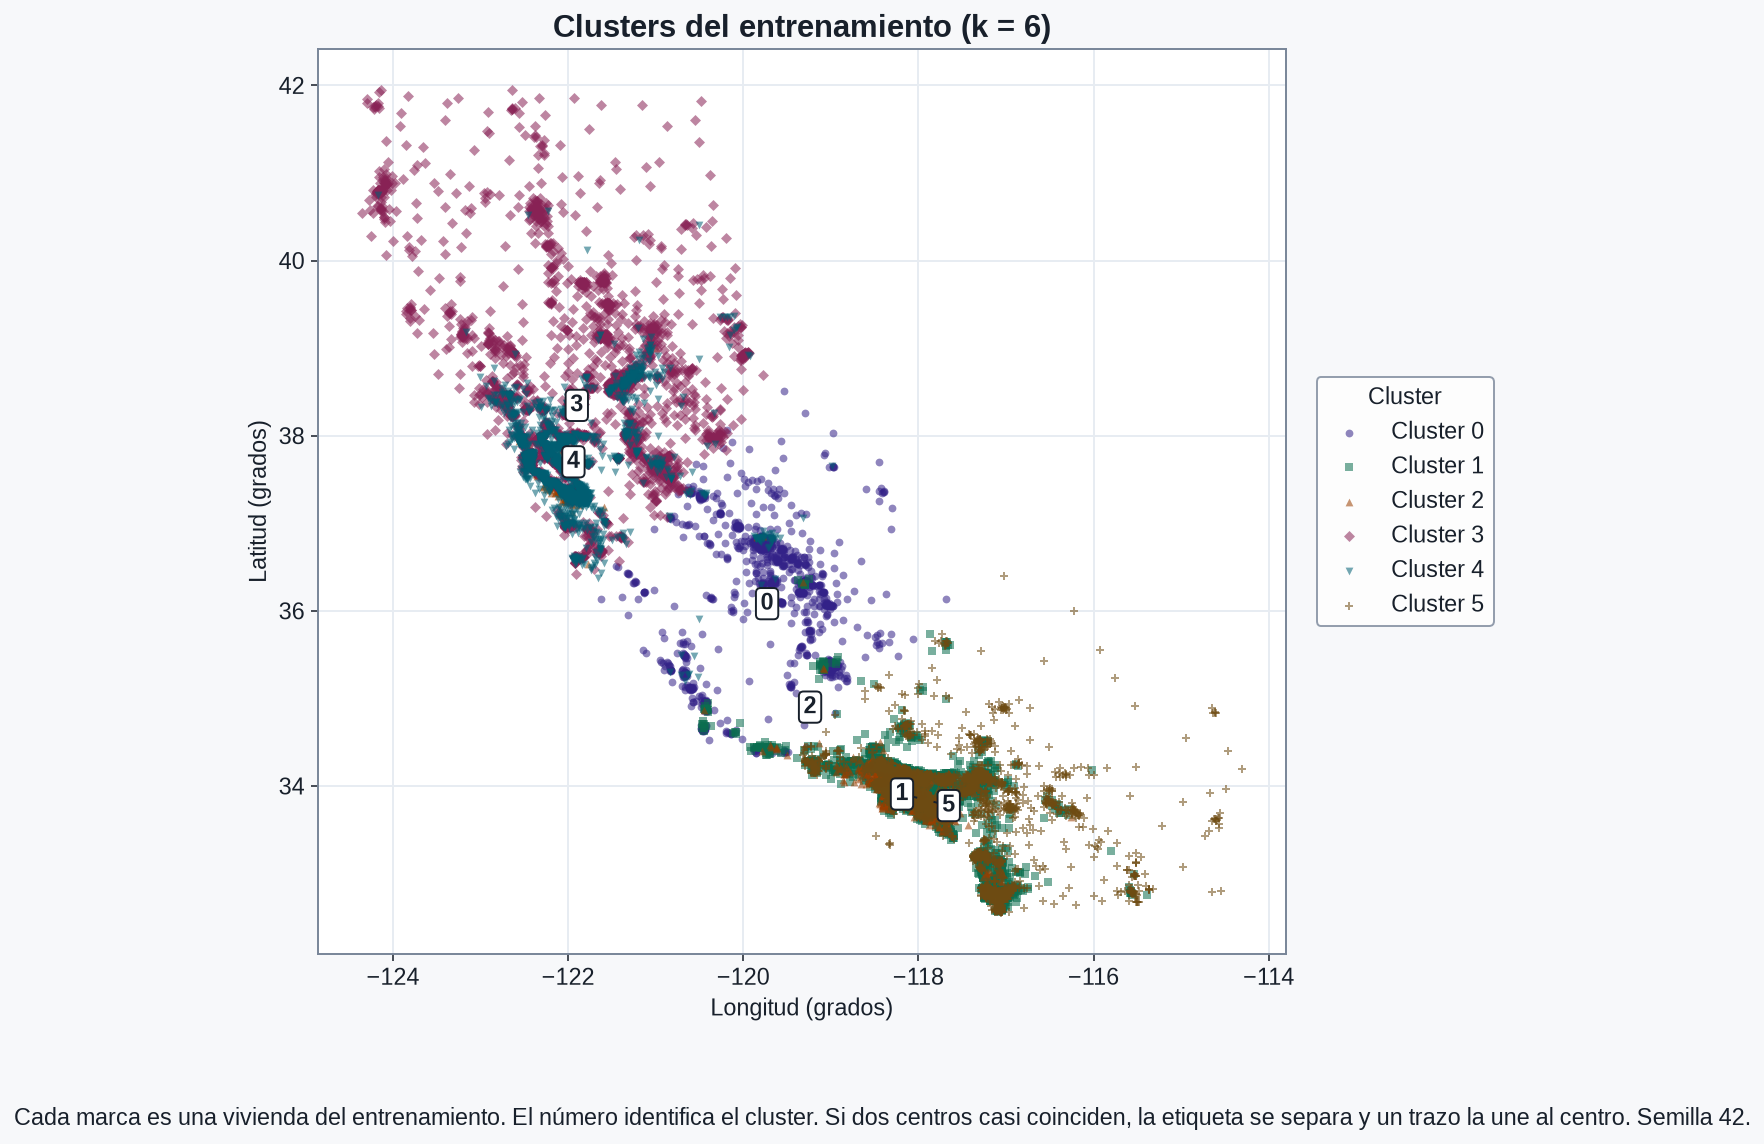

In [3]:
print(result["kmeans_text"])
print("dtype de la predicción:", result["cluster_dtype_before"])
print("dtype de la columna:", result["cluster_dtype_after"])
print("valores:", result["cluster_values"])
print("conteo en entrenamiento")
display(result["train_counts"].to_frame("n"))
print(result["lectura_escala"])
display(result["scale_train"])
from IPython.display import Image
display(Image(filename=str(ROOT / result["paths"]["clusters_train"])))


## Diagnóstico de k

Inercia y silhouette en el mismo espacio estandarizado del entrenamiento. Sirve para ver la curva. El modelo guardado sigue en k = 6.


,k,inertia,silhouette
0,2,21504.215047,0.547298
1,3,15247.451783,0.515427
2,4,11639.219458,0.432799
3,5,9509.207938,0.386941
4,6,8069.187859,0.398737
5,7,7020.677151,0.371762
6,8,6201.625535,0.355237
7,9,5630.970811,0.358062
8,10,5117.289568,0.340973


La inercia baja de 21504 en k=2 a 5117 en k=10. El mayor descenso relativo entre k consecutivos está entre k=2 y k=3 (29.1 %). El silhouette máximo del rango es 0.547 en k=2. El modelo guardado usa k=6, con silhouette 0.399 e inercia 8069, porque ese k lo fija el enunciado. De k=5 a k=6 el silhouette pasa de 0.387 a 0.399 y en k=7 baja a 0.372. Es un repunte local, no el máximo del rango. Este diagnóstico no lo sustituye.


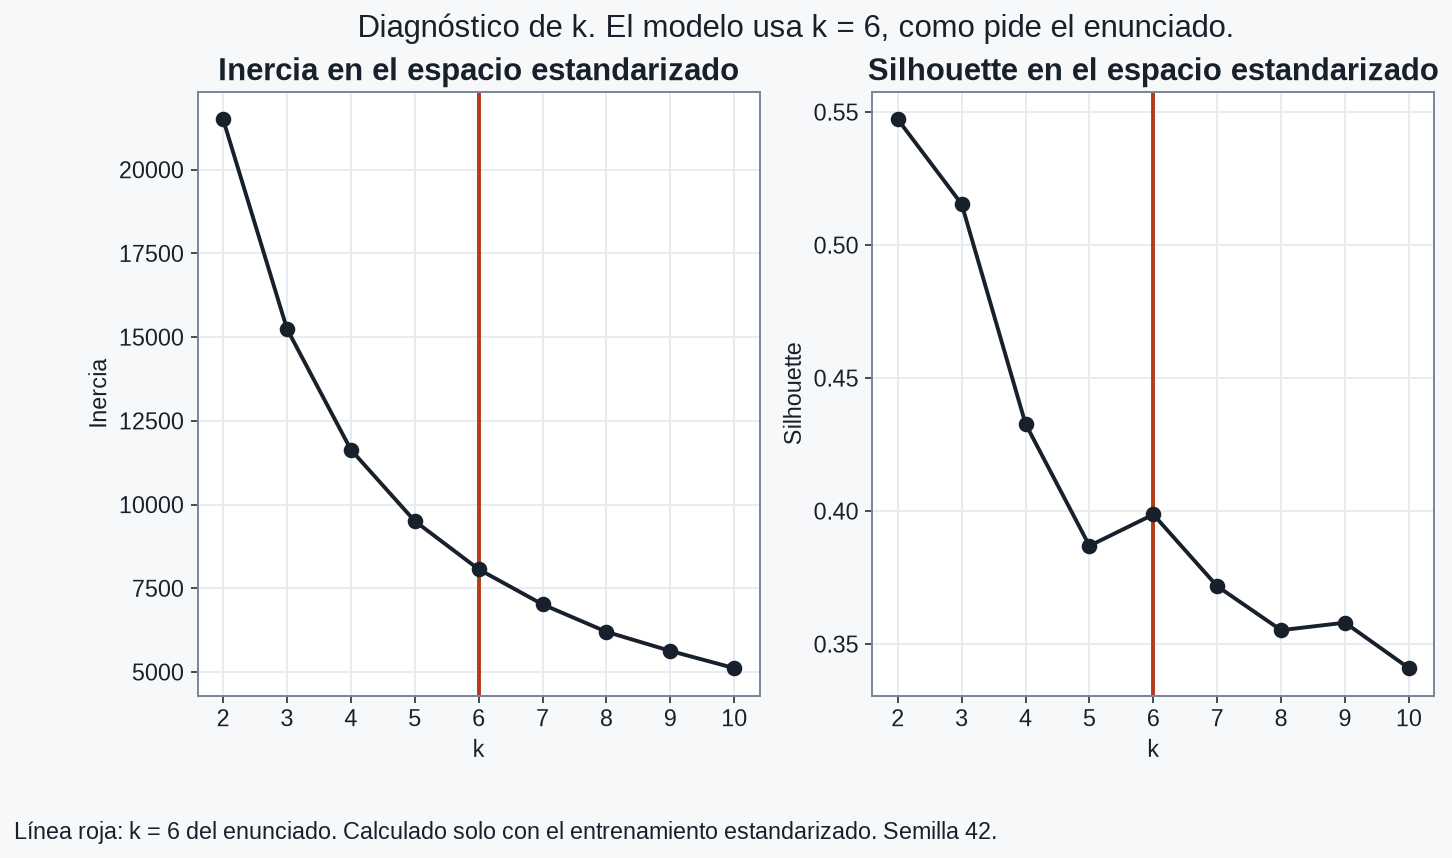

In [4]:
display(result["diagnostics"])
print(result["lectura_k"])
from IPython.display import Image
display(Image(filename=str(ROOT / result["paths"]["k_diagnostics"])))


## Paso 3. Predicción en el conjunto de prueba

El K-Means ya entrenado asigna un cluster a cada vivienda de prueba. Esas cruces se dibujan encima del entrenamiento.


conteo en prueba


,n
cluster,
0,337
1,829
2,112
3,962
4,514
5,1374


,cluster,n_train,n_test,mean_latitude,mean_longitude,mean_medinc
0,0,1321,337,36.081628,-119.727593,2.625024
1,1,3380,829,33.867888,-118.024189,5.311771
2,2,453,112,34.900552,-119.237020,10.443602
3,3,3931,962,38.345976,-121.900725,2.835044
4,4,2239,514,37.701858,-121.939053,5.518264
5,5,5188,1374,33.816490,-117.816733,2.780777


El entrenamiento tiene 16512 viviendas y la prueba 4128. K-Means se ajusta solo con el entrenamiento y después asigna la prueba.

El grupo más al norte es el 3 (latitud media 38.35, longitud media -121.90, MedInc medio 2.84, n=3931 en entrenamiento). El más al sur es el 5 (latitud 33.82, MedInc 2.78). El más al oeste es el 4 (longitud -121.94) y el más al este es el 5 (longitud -117.82). Longitud más baja quiere decir más al oeste, hacia el Pacífico, porque el gráfico usa grados sin proyección.

El MedInc medio más alto está en el cluster 2 (10.44, n=453) y el más bajo en el 0 (2.63). En el archivo, MedInc va de 0.4999 a 15.0001. Ese tope coincide con el California Housing público, donde la unidad son decenas de miles de dólares de 1990.

En el mapa hay grupos que ocupan la misma zona y se distinguen por el ingreso, porque el gráfico solo muestra latitud y longitud y MedInc también entra en la distancia. Los clusters 1 y 5 tienen centros a 0.21 grados (MedInc medio 5.31 y 2.78; n=3380 

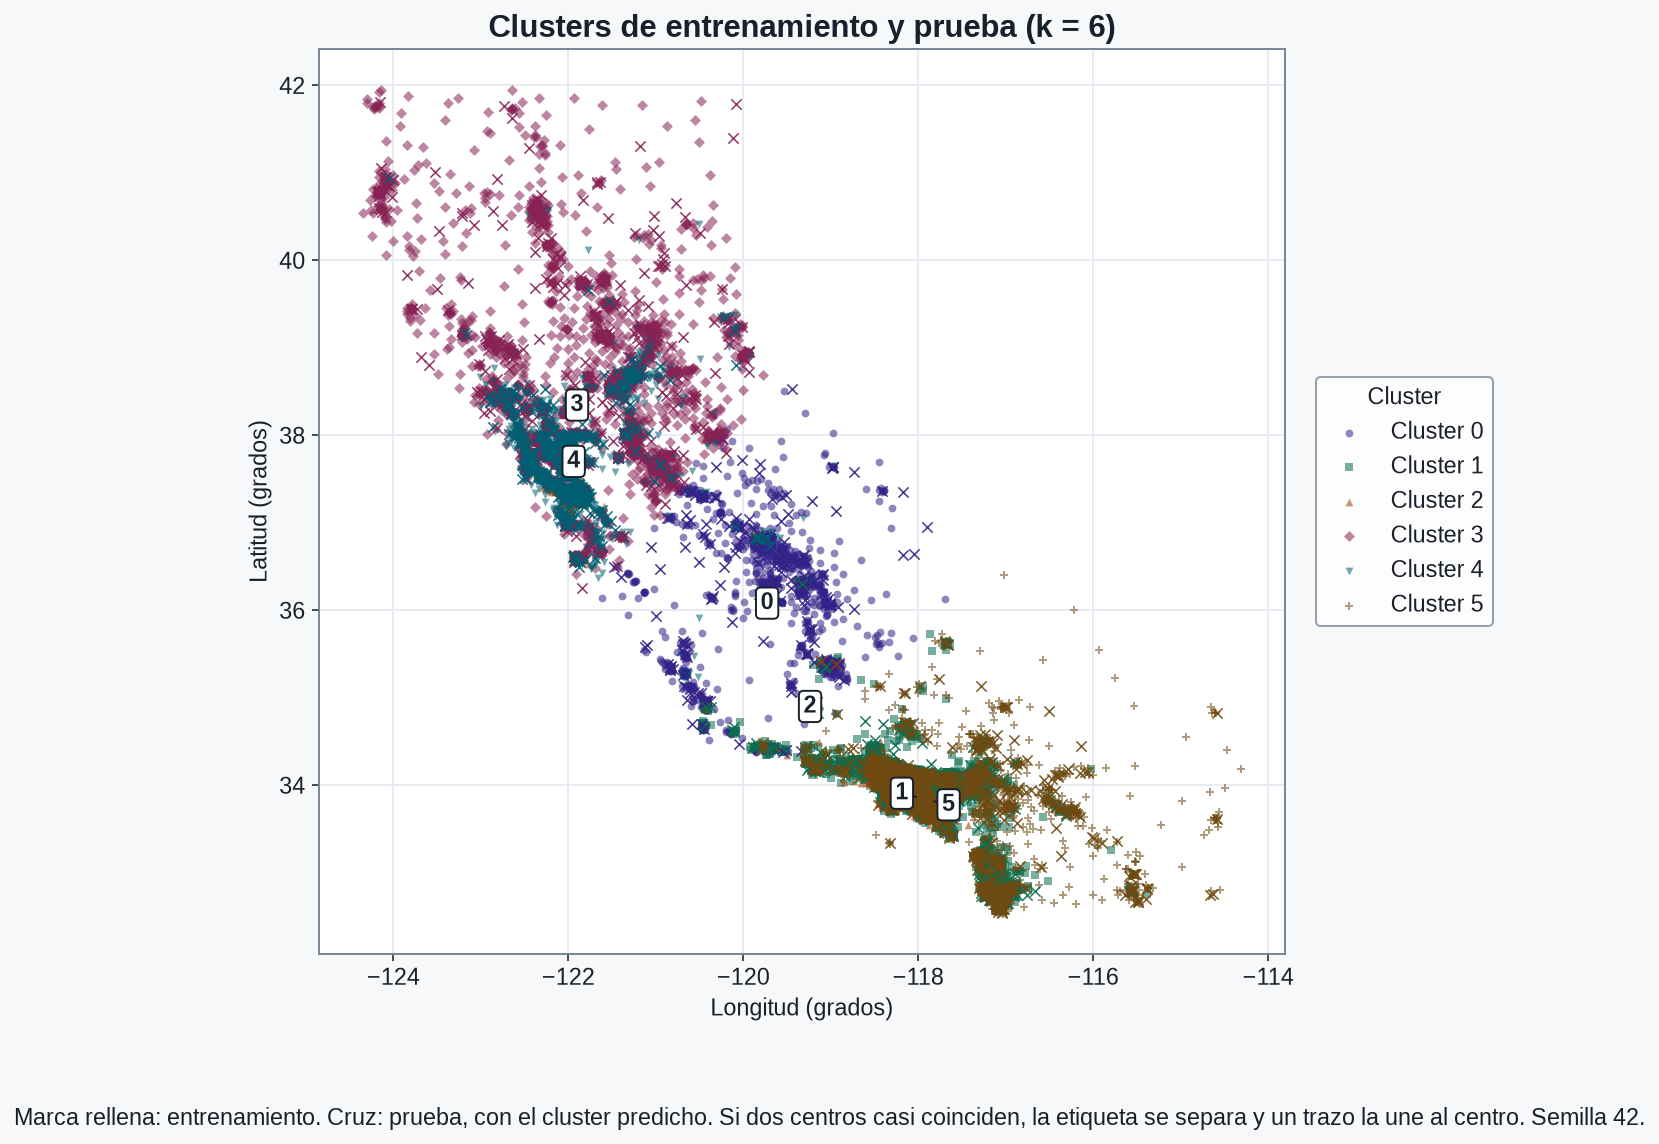

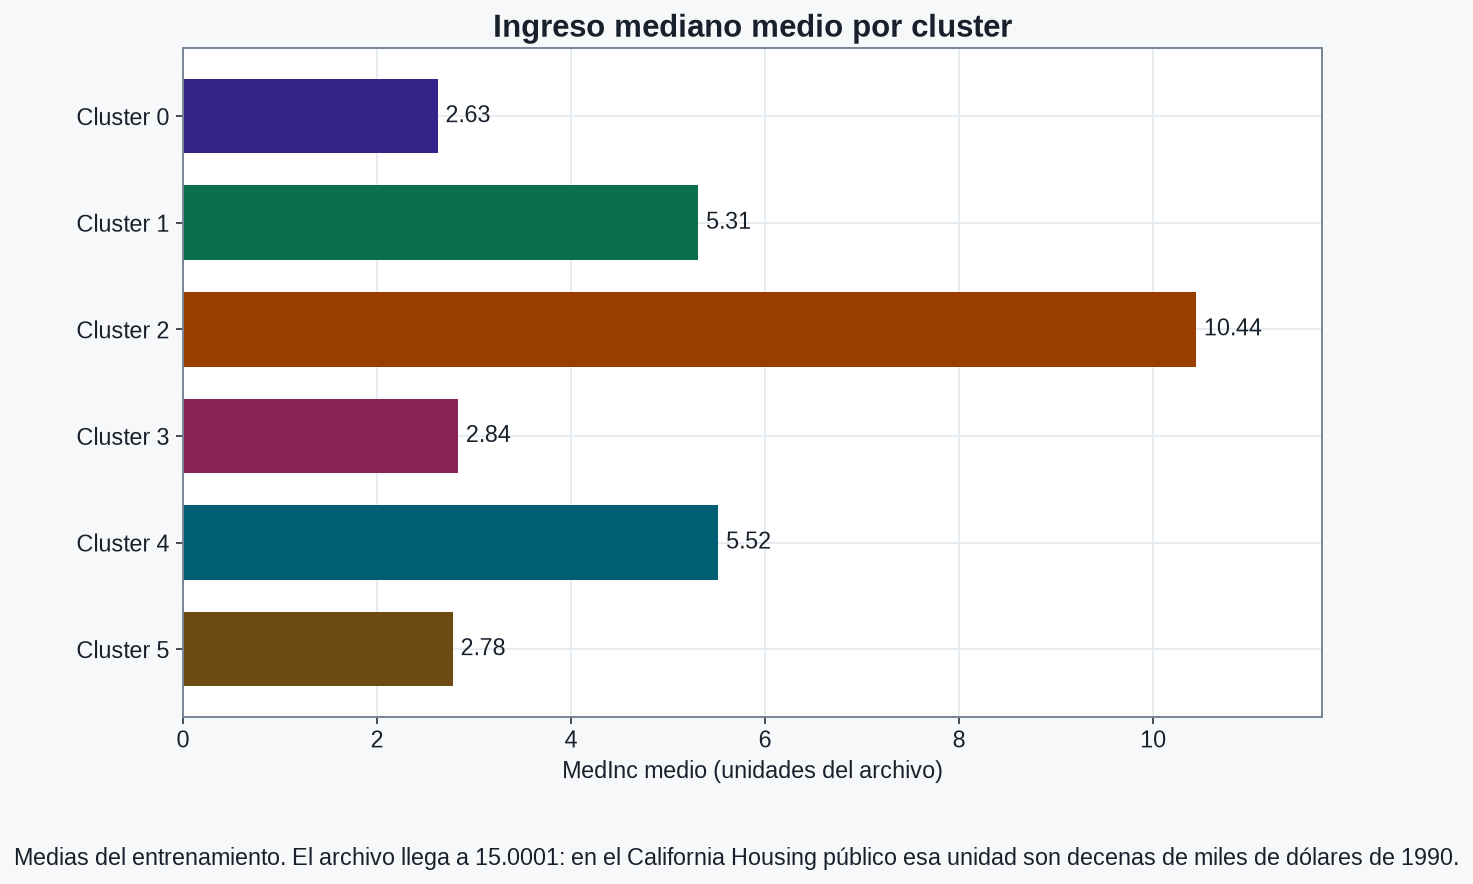

In [5]:
print("conteo en prueba")
display(result["test_counts"].to_frame("n"))
display(result["cluster_summary"])
print(result["lectura_clusters"])
from IPython.display import Image
display(Image(filename=str(ROOT / result["paths"]["clusters_train_test"])))
display(Image(filename=str(ROOT / result["paths"]["cluster_income"])))


## Paso 4. Clasificador supervisado

Se comparan regresión logística, árbol de decisión, k vecinos (15) y un bosque de 100 árboles. La elección usa el F1 macro medio de una validación cruzada estratificada de 5 pliegues sobre el entrenamiento. La prueba se evalúa una vez, después de elegir.

El objetivo es el número de cluster. `MedHouseVal` no entra.


,name,label,f1_macro_mean,f1_macro_std,fold_0,fold_1,fold_2,fold_3,fold_4
0,logistic_regression,Regresión logística,0.983420,0.005000,0.984126,0.975288,0.985373,0.983455,0.988856
1,decision_tree,Árbol de decisión,0.987147,0.003619,0.991960,0.983257,0.989304,0.987138,0.984078
2,knn,k vecinos más cercanos (15),0.984122,0.003021,0.987281,0.979945,0.986856,0.983517,0.983014
3,random_forest,Bosque aleatorio (100 árboles),0.990461,0.001238,0.988789,0.990434,0.989803,0.991396,0.991884


Se elige el clasificador con mayor F1 macro medio en validación cruzada estratificada de 5 pliegues sobre el entrenamiento. Si el F1 medio empata, se prefiere la menor desviación típica de los pliegues y, después, el modelo más simple de esta lista: regresión logística, árbol de decisión, k vecinos, bosque aleatorio. El conjunto de prueba no entra en la elección.
elegido: Bosque aleatorio (100 árboles) (random_forest)
RandomForestClassifier(n_jobs=1, random_state=42)
              precision    recall  f1-score   support

           0      0.994     0.985     0.990       337
           1      0.995     0.996     0.996       829
           2      1.000     0.982     0.991       112
           3      0.995     0.993     0.994       962
           4      0.987     0.996     0.991       514
           5      0.999     0.999     0.999      1374

    accuracy                          0.995      4128
   macro avg      0.995     0.992     0.993      4128
weighted avg      0.995     0.995     0.

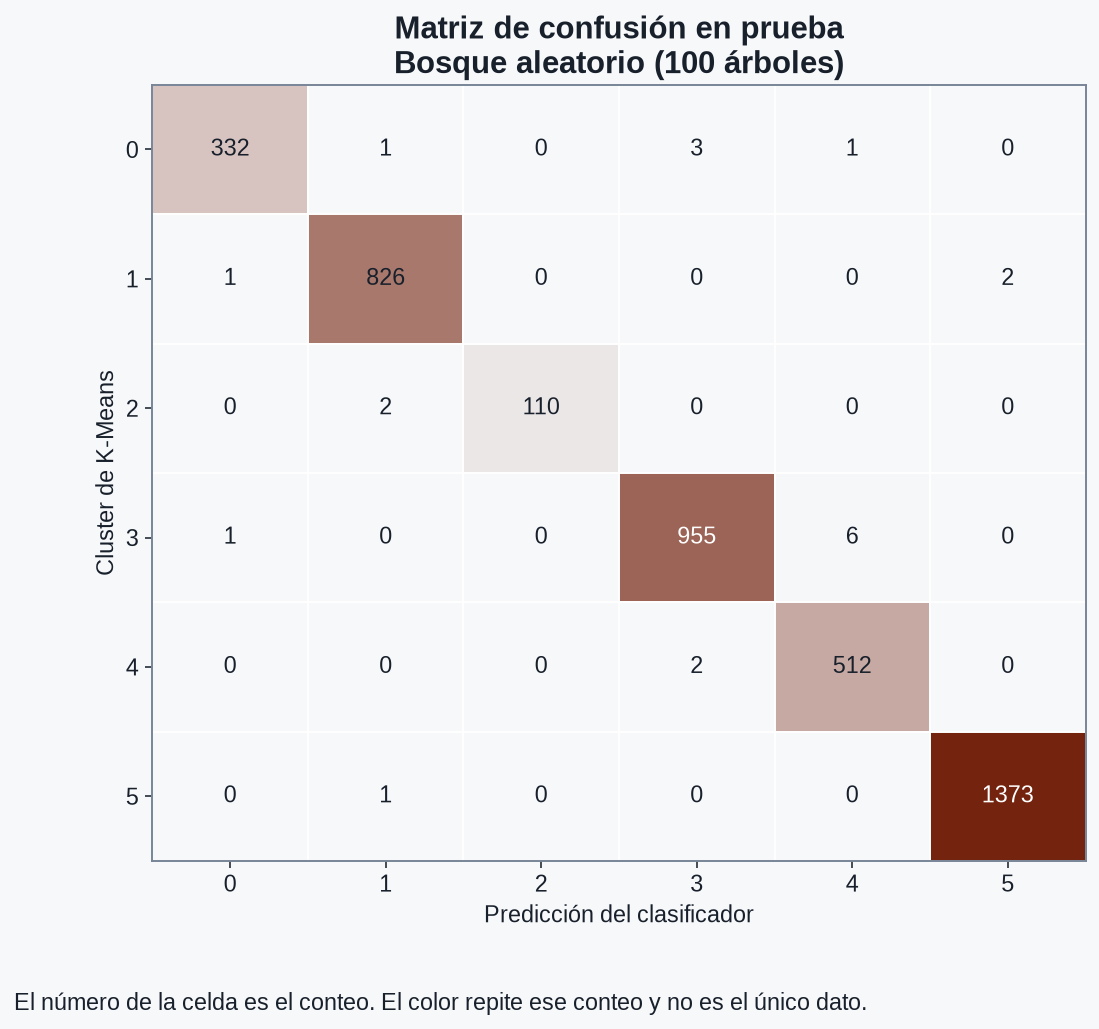

In [6]:
display(result["comparison"].drop(columns=["simplicity"]))
print(result["selection_rule"])
print("elegido:", result["selected_label"], f"({result['selected_name']})")
print(result["supervised_text"])
print(result["classification_report"])
print(result["importance_note"])
print(result["lectura_modelo"])
from IPython.display import Image
display(Image(filename=str(ROOT / result["paths"]["confusion_matrix"])))


## Paso 5. Modelos guardados

Los dos estimadores quedan en `models/`. Al recargarlos, la predicción sobre la prueba coincide con la del objeto recién ajustado.


In [7]:
print("kmeans", result["models"]["kmeans"], "reload", result["reload_kmeans_ok"])
print("supervisado", result["models"]["supervised"], "reload", result["reload_supervised_ok"])
print("dataset con cluster", result["processed_csv"])
for name, path in result["paths"].items():
    print(f"{name}: {path}")


kmeans models/kmeans.joblib reload True
supervisado models/supervised_classifier.joblib reload True
dataset con cluster data/processed/housing_with_cluster.csv
clusters_train: reports/figures/clusters_train.png
clusters_train_test: reports/figures/clusters_train_test.png
cluster_income: reports/figures/cluster_income.png
k_diagnostics: reports/figures/k_diagnostics.png
confusion_matrix: reports/figures/confusion_matrix.png
